# 04 - Modeling (Part A)
Random vs domain-disjoint split, Logistic Regression / Random Forest / XGBoost. All logic lives in `src/`; this notebook runs it and shows the outputs. Written analysis is in the README.

In [1]:
import os, sys
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix, precision_recall_curve, roc_curve
from src.common import *
from src.train_models import build_models
pd.set_option("display.width", 200)

## Data

In [2]:
df = load_data()
print("shape:", df.shape)
print("phishing rate:", round(df[TARGET].mean(), 4))
print("unique registered domains:", df["registered_domain"].nunique())
df[TARGET].value_counts()

shape: (235370, 27)
phishing rate: 0.4271
unique registered domains: 197301


is_phishing
0    134850
1    100520
Name: count, dtype: int64

## Splits

In [3]:
splits = {"random": random_split(df), "domain_disjoint": domain_disjoint_split(df)}
for name, (Xtr, Xte, ytr, yte) in splits.items():
    print(f"{name:16s} train {Xtr.shape}  test {Xte.shape}  phishing rate train {ytr.mean():.4f} test {yte.mean():.4f}")

Xtr, Xte, _, _ = splits["domain_disjoint"]
dom = df["registered_domain"]
print("domains shared between train and test (domain-disjoint):", len(set(dom.loc[Xtr.index]) & set(dom.loc[Xte.index])))

random           train (188296, 23)  test (47074, 23)  phishing rate train 0.4271 test 0.4271
domain_disjoint  train (187307, 23)  test (48063, 23)  phishing rate train 0.4240 test 0.4389
domains shared between train and test (domain-disjoint): 0


## Train and evaluate (scalers/encoders fit on train only, inside a Pipeline)

In [4]:
rows, preds = [], {}
for s, (Xtr, Xte, ytr, yte) in splits.items():
    for n, m in build_models(Xtr).items():
        print("training", n, "on", s)
        m.fit(Xtr, ytr)
        rows.append({"model": n, "split": s, **evaluate(m, Xte, yte)})
        preds[(n, s)] = (yte.values, m.predict_proba(Xte)[:, 1])
res = pd.DataFrame(rows)
res.drop(columns=["tn", "fp", "fn", "tp"]).round(4)

training LogReg on random


training RandomForest on random


training XGBoost on random


training LogReg on domain_disjoint


training RandomForest on domain_disjoint


training XGBoost on domain_disjoint


,model,split,precision,recall,f1,macro_f1,fnr,pr_auc,roc_auc
0,LogReg,random,1.0000,0.9996,0.9998,0.9998,0.0004,0.9999,0.9999
1,RandomForest,random,1.0000,0.9998,0.9999,0.9999,0.0002,1.0000,1.0000
2,XGBoost,random,1.0000,0.9998,0.9999,0.9999,0.0002,1.0000,0.9999
3,LogReg,domain_disjoint,1.0000,0.9992,0.9996,0.9997,0.0008,0.9999,0.9998
4,RandomForest,domain_disjoint,0.9999,0.9999,0.9999,0.9999,0.0001,1.0000,1.0000
5,XGBoost,domain_disjoint,1.0000,0.9999,1.0000,1.0000,0.0001,1.0000,1.0000


## Error counts and F1 gap (random - domain-disjoint)

In [5]:
display(res[["model", "split", "fp", "fn", "tp", "tn"]])
piv = res.pivot(index="model", columns="split", values="f1")
piv["gap"] = piv["random"] - piv["domain_disjoint"]
piv.round(6)

,model,split,fp,fn,tp,tn
0,LogReg,random,0,9,20095,26970
1,RandomForest,random,1,4,20100,26969
2,XGBoost,random,0,4,20100,26970
3,LogReg,domain_disjoint,0,16,21081,26966
4,RandomForest,domain_disjoint,2,2,21095,26964
5,XGBoost,domain_disjoint,0,2,21095,26966


split,domain_disjoint,random,gap
model,,,
LogReg,0.999621,0.999776,0.000155
RandomForest,0.999905,0.999876,-0.000030
XGBoost,0.999953,0.999901,-0.000052


## Confusion matrices

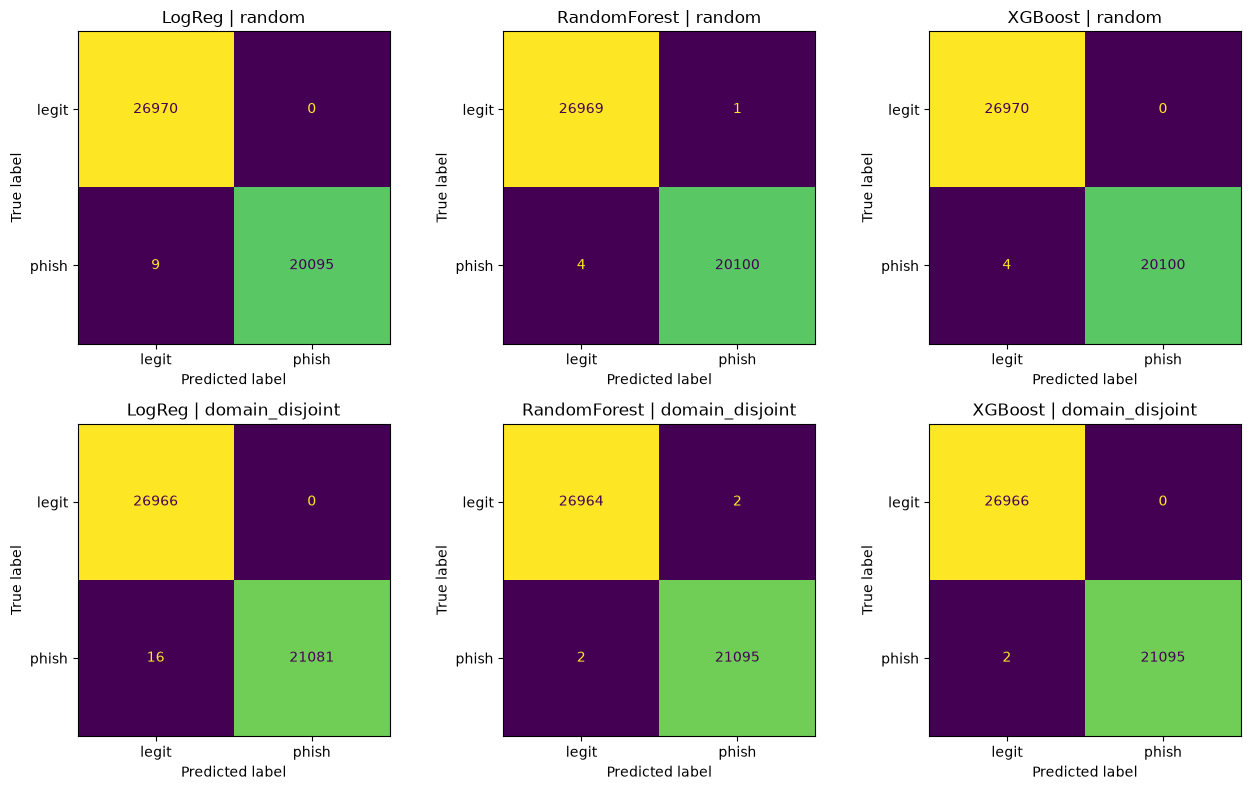

In [6]:
models = ["LogReg", "RandomForest", "XGBoost"]
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for i, s in enumerate(["random", "domain_disjoint"]):
    for j, m in enumerate(models):
        y, p = preds[(m, s)]
        ConfusionMatrixDisplay(confusion_matrix(y, (p >= 0.5).astype(int)),
                               display_labels=["legit", "phish"]).plot(ax=axes[i, j], colorbar=False, values_format="d")
        axes[i, j].set_title(f"{m} | {s}")
plt.tight_layout(); plt.show()

## PR and ROC curves (zoomed to the top-right corner)

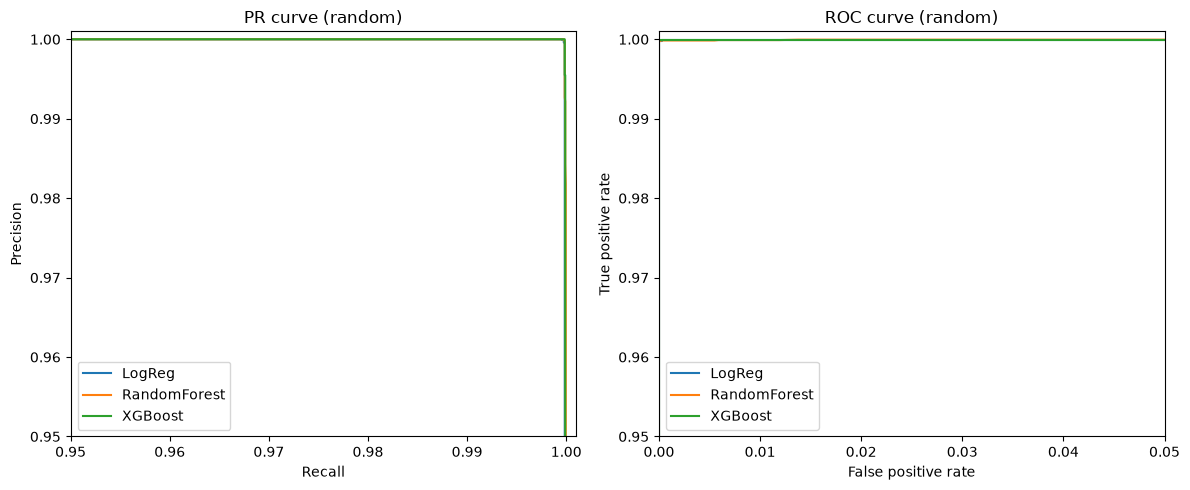

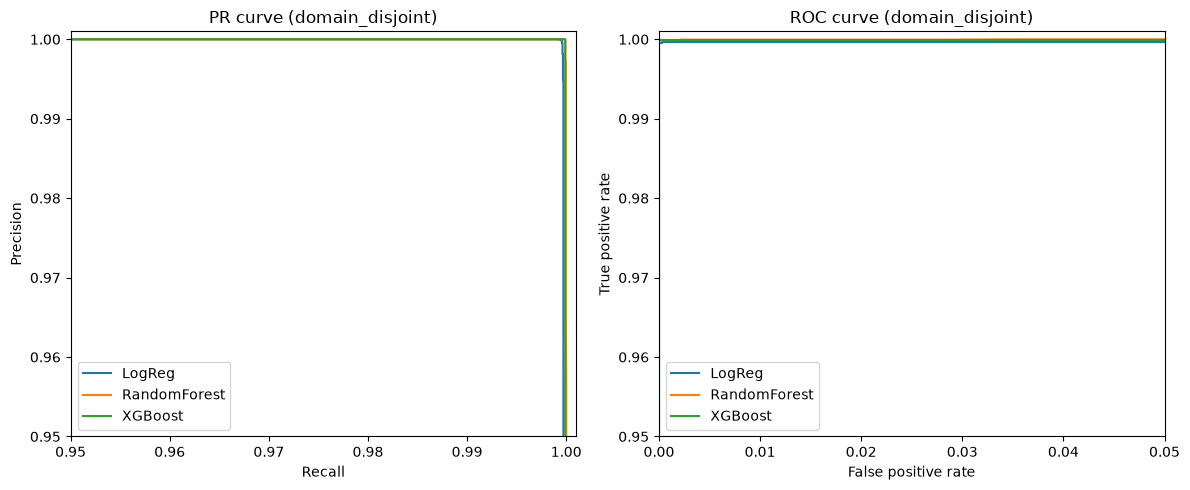

In [7]:
for s in ["random", "domain_disjoint"]:
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 5))
    for m in models:
        y, p = preds[(m, s)]
        pr, rc, _ = precision_recall_curve(y, p)
        fpr, tpr, _ = roc_curve(y, p)
        a1.plot(rc, pr, label=m); a2.plot(fpr, tpr, label=m)
    a1.set(xlabel="Recall", ylabel="Precision", title=f"PR curve ({s})", xlim=(0.95, 1.001), ylim=(0.95, 1.001))
    a2.set(xlabel="False positive rate", ylabel="True positive rate", title=f"ROC curve ({s})", xlim=(0, 0.05), ylim=(0.95, 1.001))
    a1.legend(); a2.legend(); plt.tight_layout(); plt.show()

## Error analysis: XGBoost on the domain-disjoint split

In [8]:
Xte = splits["domain_disjoint"][1]
y, p = preds[("XGBoost", "domain_disjoint")]
pred = (p >= 0.5).astype(int)
cols = ["URL", "URLLength", "NoOfOtherSpecialCharsInURL", "URLSimilarityIndex", "TLDLegitimateProb", "URLCharProb", "IsHTTPS"]
fn = (pred == 0) & (y == 1)
print("false negatives:", fn.sum())
display(df.loc[Xte.index[fn], cols].assign(phish_prob=p[fn]))
fp = (pred == 1) & (y == 0)
print("false positives:", fp.sum())
print("\nMedian features in the test set by class:")
df.loc[Xte.index].groupby(TARGET)[["URLLength", "NoOfOtherSpecialCharsInURL", "URLSimilarityIndex", "IsHTTPS"]].median()

false negatives: 2


,URL,URLLength,NoOfOtherSpecialCharsInURL,URLSimilarityIndex,TLDLegitimateProb,URLCharProb,IsHTTPS,phish_prob
62376,https://www.opallegal.com.au,28,2,100.0,0.010086,0.063366,1,0.000258
168242,https://www.opallegal.com.au/,29,3,100.0,0.010086,0.063366,1,0.000132


false positives: 0

Median features in the test set by class:


,URLLength,NoOfOtherSpecialCharsInURL,URLSimilarityIndex,IsHTTPS
is_phishing,,,,
0,26.0,1.0,100.00000,1.0
1,34.0,3.0,51.71088,0.0
